In [4]:
import uproot
import numpy as np
import glob
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [14]:
base = "/Users/PITLab/3D_sensors/Processed_data/"
fields = [
    'i_evt',
    'channel',
    'time',
    'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    'risetime',
    'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]

nbins = 40
plot_size = 7

In [25]:
filenames = []
pattern = f"{base}/proc_F_*AC100W80*_low_threshold.root"
filenames += glob.glob(pattern)


# filenames = np.array(filenames)

bias_voltages = []
legend_labels = []
object_labels = []

for f in filenames:
    bias_voltage = f.split("_bv")[1].split("_")[0] + "V"
    wafer = f.split(f"{base}proc_F_")[1].split("_strip")[0]
    tag = f.split(f"{base}proc_F_")[1].split("_Ch8_")[1].split("_")[0]
    bias_voltages.append(int(f.split("_bv")[1].split("_")[0]))

    if "low_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 4 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"low_threshold")
    elif "high_threshold_trigger" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 20 mV, Ch8: 40 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_trigger")
    elif "high_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_MCP")
    elif "_.root" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 15 mV, Ch8: 20 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_earlyruns")
    else:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 12.5 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"init_threshold")

bias_voltages = np.array(bias_voltages)
sort = np.argsort(bias_voltages)
legend_labels = np.array(legend_labels)[sort]
object_labels = np.array(object_labels)[sort]
filenames     = np.array(filenames)    [sort]
bias_voltages = bias_voltages[sort]

print(filenames)
print(legend_labels)
print(object_labels)
print(bias_voltages[sort])

['/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv110_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv113_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_low_threshold.root'
 '/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root']
['AC100W80 105V Ru106 Ch4: 10 mV, Ch8: 4 mV'
 'AC100W80 110V Ru106 Ch4: 10 mV, Ch8: 4 mV'
 'AC100W80 113V Ru106 Ch4: 10 mV, Ch8: 4 mV'
 'AC100W80 116V Sr90 Ch4: 10 mV, Ch8: 4 mV'
 'AC100W80 116V Ru106 Ch4: 10 mV, Ch8: 4 mV']
['AC100W80_105V_Ru106_low_threshold' 'AC100W80_110V_Ru106_low_threshold'
 'AC100W80_113V_Ru106_low_threshold' 'AC100W80_116V_Sr90_low_threshold'
 'AC100W80_116V_Ru106_low_threshold

In [26]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}

trigger_strip = 3
mcp_channel = 7

for f_i, f in enumerate(filenames):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    # print(pulse[0].fields)
    l = str(object_labels[f_i])
    integral[l] = pulse["integral"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]

print(amp.keys())

dict_keys(['AC100W80_105V_Ru106_low_threshold', 'AC100W80_110V_Ru106_low_threshold', 'AC100W80_113V_Ru106_low_threshold', 'AC100W80_116V_Sr90_low_threshold', 'AC100W80_116V_Ru106_low_threshold'])


-0.19450928892189334
-0.19812298512501683
-0.21651974378536779
-0.26287750082631267
-0.2906563701747938


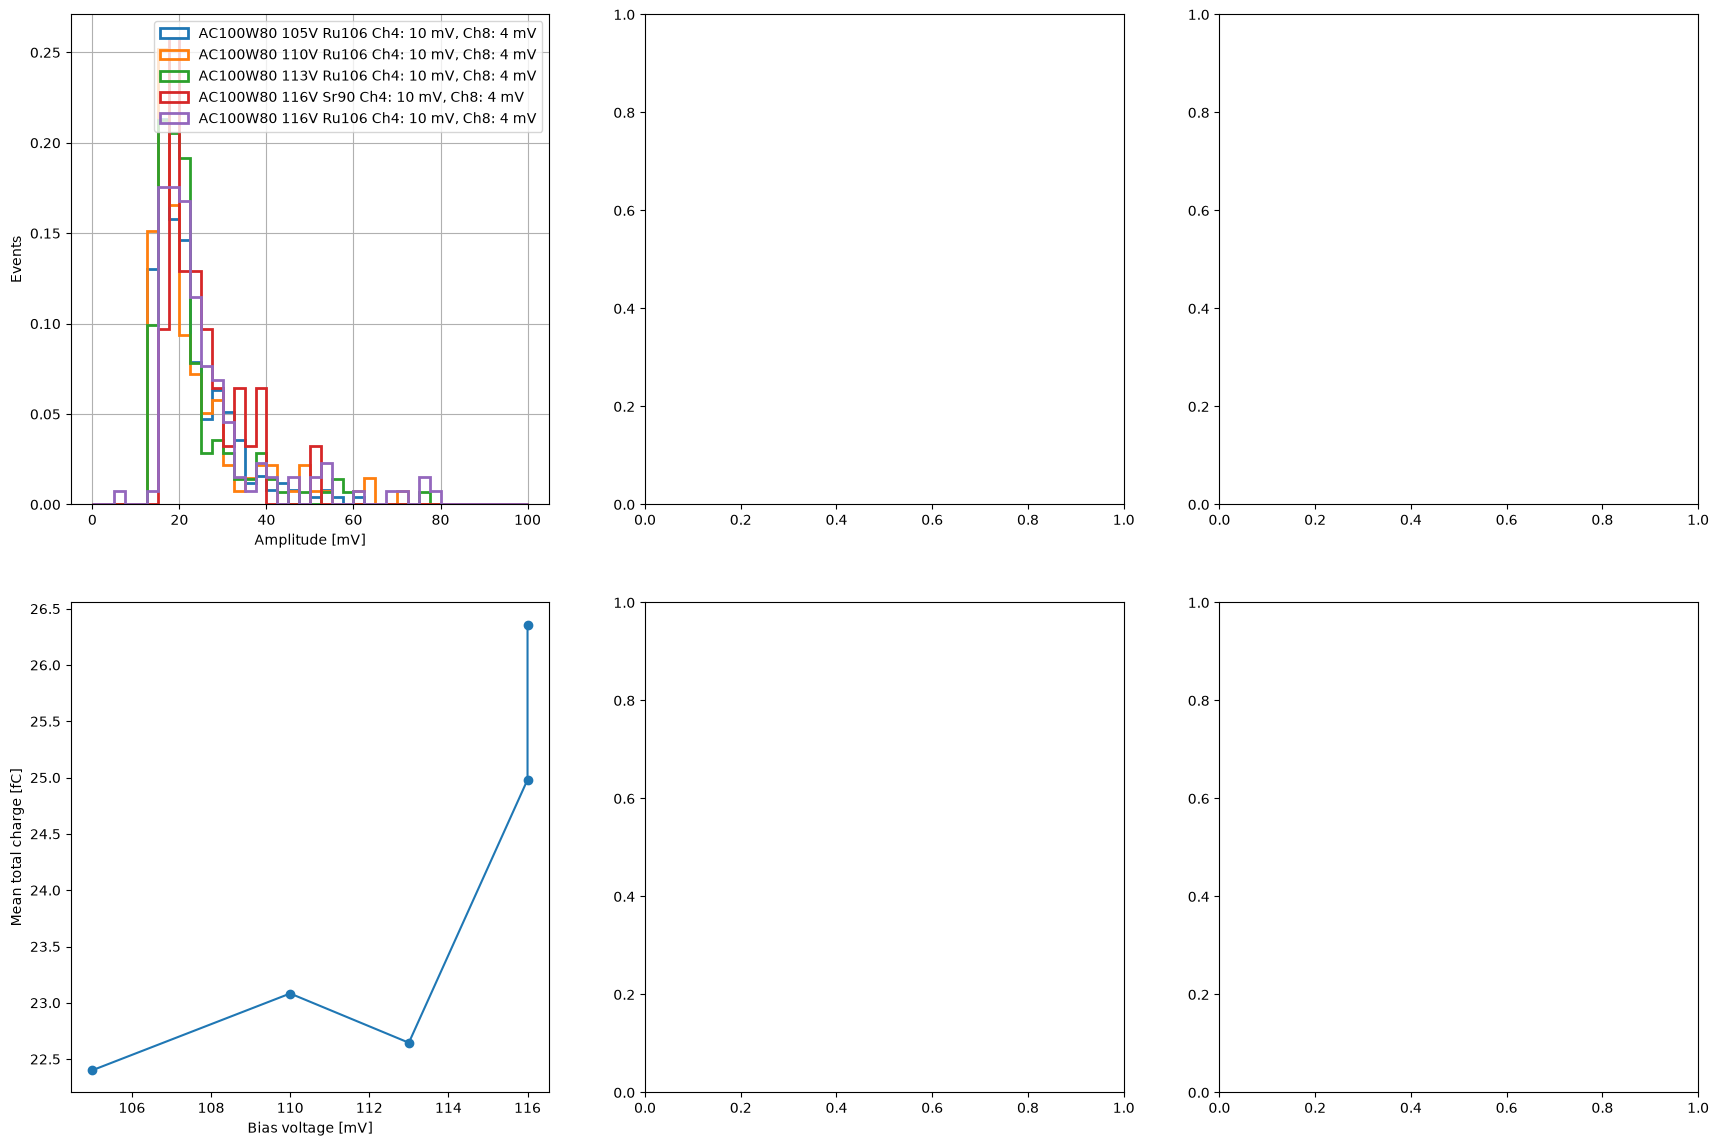

In [34]:
rows = 2
cols = 3
plot_size = 7
fig, ax = plt.subplots(rows, cols, figsize = (plot_size*cols, plot_size*rows))
width = "W80"
threshold = "low_threshold"

bias = []
mean_total_charge = []
mean_trigger_charge = []
mean_amplitude = []

for key_i, key in enumerate(object_labels):
    # if threshold not in key and "high_threshold_earlyruns" not in key: continue
    # if threshold not in key and "high_threshold_MCP" not in key: continue
    if threshold not in key: continue
    if width not in key: continue
    # Selections -----------------------
    noise_removal = baseline_RMS[key][:, trigger_strip] < 3
    lead_1 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip-3]
    lead_2 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip-2]
    lead_3 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip-1]
    lead_4 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip+1]
    lead_5 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip+2]
    lead_6 = amp[key][:, trigger_strip] > amp[key][:, trigger_strip+3]
    amp_fraction = amp[key][:, trigger_strip] / (amp[key][:, trigger_strip-1] + amp[key][:, trigger_strip] + amp[key][:, trigger_strip+1]) < 0.5
    amp_cut = amp[key][:, trigger_strip] < 80

    selections = noise_removal & lead_1 & lead_2 & lead_3 & lead_4 & lead_5 & lead_6 & amp_fraction & amp_cut
    # ----------------------------------- 
    
    variable = integral[key][:, trigger_strip][selections]
    weights = np.ones(len(variable))/len(variable)
    bias.append(bias_voltages[key_i])
    print(np.mean(variable))
    
    # variable = np.sum(integral[key][:,0:6][selections], axis = 1)
    # mean_total_charge.append(np.mean(variable))
    # # print(integral[key][selections][:,0:6])
    # ax[0][0].hist(variable, bins = nbins, histtype = "step", label = legend_labels[key_i], range = (-4, 0),  weights = weights, linewidth=2)
    # ax[0][0].set_xlabel("Total charge [fC]")
    # ax[0][0].set_ylabel("Events")
    
    # variable = integral[key][:, trigger_strip][selections]
    # mean_trigger_charge.append(np.mean(variable))
    # ax[0][1].hist(variable, bins = nbins, histtype = "step", label = legend_labels[key_i], range = (-2, 0), weights = weights, linewidth=2)
    # ax[0][1].set_xlabel("Charge in trigger channel [fC]")
    # ax[0][1].set_ylabel("Events")
    
    variable = amp[key][:, trigger_strip][selections]
    mean_amplitude.append(np.mean(variable))
    # print(np.mean(variable))
    ax[0][0].hist(variable, bins = nbins, histtype = "step", label = legend_labels[key_i], range = (0, 100), weights = weights, linewidth=2)
    ax[0][0].set_xlabel("Amplitude [mV]")
    ax[0][0].set_ylabel("Events")
    
    ax[0][0].legend()
    # ax[0][1].legend()
    # ax[0][2].legend()

    ax[0][0].grid(True, linestyle='-', alpha=1.0)
    # ax[0][1].grid(True, linestyle='-', alpha=1.0)
    # ax[0][2].grid(True, linestyle='-', alpha=1.0)

ax[1][0].plot(bias, np.abs(mean_amplitude), "-o")
ax[1][0].set_xlabel("Bias voltage [mV]")
ax[1][0].set_ylabel("Mean total charge [fC]")

# ax[1][1].plot(bias, np.abs(mean_trigger_charge), "-o")
# ax[1][1].set_xlabel("Bias voltage [mV]")
# ax[1][1].set_ylabel("Mean trigger charge [fC]")

# ax[1][2].plot(bias, mean_amplitude, "-o")
# ax[1][2].set_xlabel("Bias voltage [mV]")
# ax[1][2].set_ylabel("Mean trigger amplitude [fC]")

# ax[1][0].grid(True, linestyle='-', alpha=1.0)
# ax[1][1].grid(True, linestyle='-', alpha=1.0)
# ax[1][2].grid(True, linestyle='-', alpha=1.0)

plt.show()

# fig.savefig(f"{width}_{threshold}_early_run.png")
fig.savefig(f"{width}_{threshold}.png")